# Fine-Grained Multi-Label Emotion Detection

## 1. Project Definition

The objective of this project is to develop and compare machine learning and deep learning approaches for fine-grained multi-label emotion classification in text.

The project uses GoEmotions dataset and compares traditional TF-IDF-based classification models with a fine-tuned DistilBERT model.

## 2. Setup and Libraries

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from pathlib import Path
from urllib.request import urlretrieve
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (classification_report, confusion_matrix,
 accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
                             average_precision_score,classification_report)
from sklearn.model_selection import GridSearchCV
import torch
from transformers import DistilBertTokenizer, DistilBertModel
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers.utils import logging
import re
import os
import time
import copy

## 3. Dataset and Exploratory Data Analysis

### 3.1 Dataset Overview

This project uses the GoEmotions dataset, which contains Reddit comments annotated with fine-grained emotion labels.
The dataset used in this project contains 28 emotion classes and supports multi-label classification, meaning that a single comment can be associated with more than one emotion.

Dataset source: https://github.com/google-research/google-research/tree/master/goemotions/data

### 3.2 Exploratory Data Analysis

In [5]:
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "google-research/google-research/master/goemotions/data"
)

for filename in ['train.tsv', 'dev.tsv', 'test.tsv']:
    file_path = DATA_DIR / filename

    if not file_path.exists():
        urlretrieve(f'{BASE_URL}/{filename}', file_path)
        print(f'Downloaded: {filename}')
    else:
        print(f'already exists: {filename}')

Downloaded: train.tsv
Downloaded: dev.tsv
Downloaded: test.tsv


In [7]:
column_names = ["text", "label", "id"]

train_df = pd.read_csv(
    DATA_DIR / "train.tsv",
    sep="\t",
    header=None,
    names=column_names
)

dev_df = pd.read_csv(
    DATA_DIR / "dev.tsv",
    sep="\t",
    header=None,
    names=column_names
)

test_df = pd.read_csv(
    DATA_DIR / "test.tsv",
    sep="\t",
    header=None,
    names=column_names
)

print("Train:", train_df.shape)
print("Validation:", dev_df.shape)
print("Test:", test_df.shape)

train_df.head()

Train: (43410, 3)
Validation: (5426, 3)
Test: (5427, 3)


,text,label,id
0,My favourite food is anything I didn't have to...,27,eebbqej
1,"Now if he does off himself, everyone will thin...",27,ed00q6i
2,WHY THE FUCK IS BAYLESS ISOING,2,eezlygj
3,To make her feel threatened,14,ed7ypvh
4,Dirty Southern Wankers,3,ed0bdzj


In [8]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43410 entries, 0 to 43409
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    43410 non-null  object
 1   label   43410 non-null  object
 2   id      43410 non-null  object
dtypes: object(3)
memory usage: 1017.6+ KB


The training set contains no missing values, so no null-value treatment is required.

**Label Format**

In [9]:
train_df.columns

Index(['text', 'label', 'id'], dtype='object')

In [10]:
train_df.iloc[0]

,0
text,My favourite food is anything I didn't have to...
label,27
id,eebbqej


In [11]:
train_df['label']= train_df['label'].apply(
    lambda x: [int(i) for i in str(x).split(',')])
print(train_df['label'].head(10))

0       [27]
1       [27]
2        [2]
3       [14]
4        [3]
5       [26]
6       [15]
7    [8, 20]
8        [0]
9       [27]
Name: label, dtype: object


In [12]:
dev_df['label'] = dev_df['label'].apply(
    lambda x: [int(i) for i in str(x).split(',')])

test_df['label'] = test_df['label'].apply(
    lambda x: [int(i) for i in str(x).split(',')])

In [13]:
all_labels = train_df.explode('label')

In [14]:
label_counts = all_labels['label'].value_counts().sort_index()

Each emotion label is encoded as an integer ID from 0 to 27, corresponding to a predefined emotion class.

**Emotion Label Distribution**

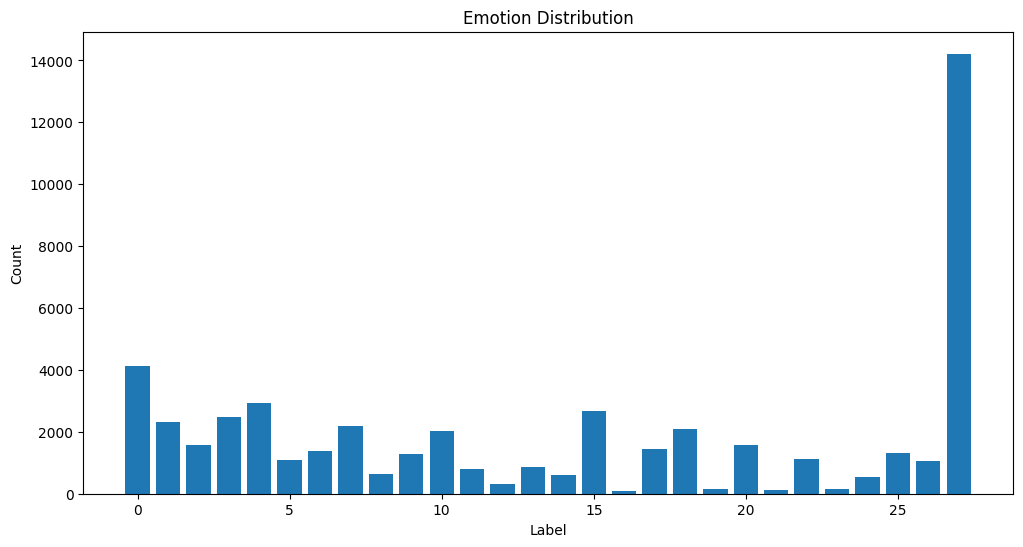

In [15]:
plt.figure(figsize=(12,6))
plt.bar(label_counts.index, label_counts.values)
plt.xlabel('Label')
plt.ylabel('Count')
plt.title('Emotion Distribution')
plt.show()

The label distribution shows substantial class imbalance across emotion categories.

**Number of Labels per Sample**

In [16]:
train_df['num_labels']=train_df['label'].apply(len)
train_df['num_labels'].value_counts().sort_index()

,count
num_labels,
1,36308
2,6541
3,532
4,28
5,1


Most comments(83.6%) are associated with a single emotion label, while a smaller proportion contains multiple labels, confirming the multi-label nature of the dataset.

---



**Label Co-Occurrence**

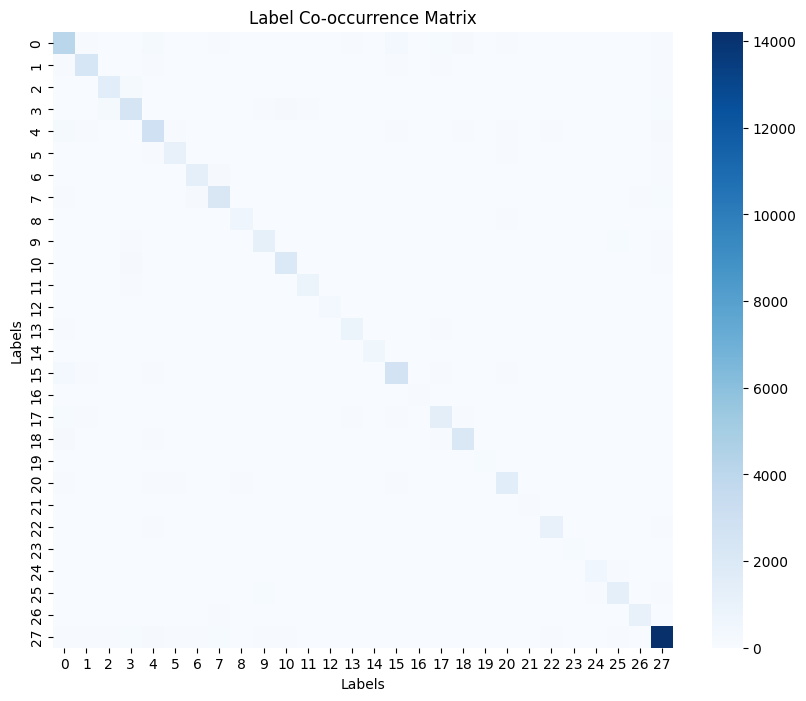

In [17]:
num_classes = 28
co_matrix = np.zeros((num_classes, num_classes))

for labels in train_df['label']:
    for i in labels:
        for j in labels:
            co_matrix[i][j] += 1

plt.figure(figsize=(10, 8))
sns.heatmap(co_matrix, cmap='Blues')
plt.xlabel('Labels')
plt.ylabel('Labels')
plt.title('Label Co-occurrence Matrix')
plt.show()

The strong diagonal reflects the high frequency of individual labels, while combinations of different emotion labels are less common.

**Most Frequent Label Pairs**

In [18]:
from collections import Counter

pairs = Counter()

for labels in train_df['label']:
    for i in range(len(labels)):
        for j in range(i + 1, len(labels)):
            pairs[tuple(sorted((labels[i], labels[j])))] += 1

    pairs.most_common(10)

**Text Length Analysis**

In [19]:
train_df['char_length']=train_df['text'].apply(len)
train_df['char_length'].describe()

,char_length
count,43410.000000
mean,68.400875
std,36.721898
min,2.000000
25%,38.000000
50%,65.000000
75%,96.000000
max,703.000000


**Word Count**

In [20]:
train_df['word_count']=train_df['text'].apply(
    lambda x: len(x.split()))
train_df['word_count'].describe()

,word_count
count,43410.000000
mean,12.840175
std,6.701597
min,1.000000
25%,7.000000
50%,12.000000
75%,18.000000
max,33.000000


**Distribution of Comment Length**

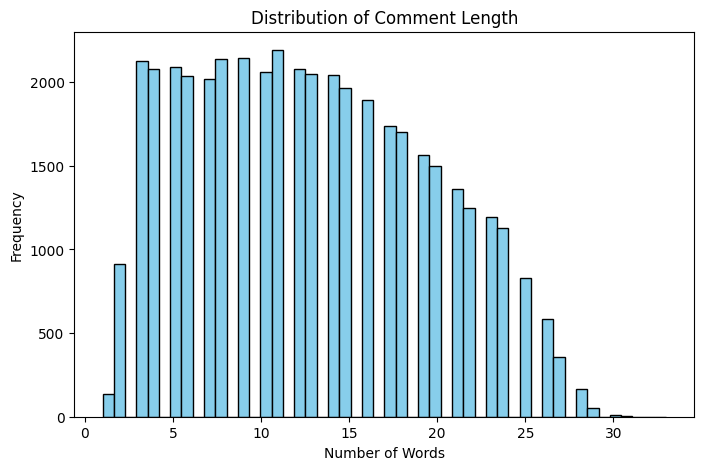

In [21]:
plt.figure(figsize=(8, 5))

plt.hist(train_df['word_count'], bins=50, color='skyblue', edgecolor='black')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.title('Distribution of Comment Length')

plt.show()

**Word-Count Percentiles**

In [22]:
train_df['word_count'].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

,word_count
0.25,7.0
0.50,12.0
0.75,18.0
0.90,22.0
0.95,24.0
0.99,27.0


As shown in the chart and the percentile table, most comments in the dataset are relatively short. The median length of comments is 12 words. Approximately 95% of the comments contain 24 words or fewer.

## 4. Data Preprocessing

### 4.1 Text Cleaning

In [23]:
def clean_text(text):
  text = str(text).lower()

  #Removing URLS

  text = re.sub(r'http\S+|www\S+','',text)

  #Removing extra spaces

  text = re.sub(r'\s+',' ',text).strip()

  return text

In [30]:
train_df['clean_text'] = train_df['text'].apply(clean_text)
dev_df['clean_text'] = dev_df['text'].apply(clean_text)
test_df['clean_text'] = test_df['text'].apply(clean_text)

Text preprocessing includes lowercasing, URL removal, and whitespace normalization. Emojis and punctuation are preserved because they may convey important emotional information.

### 4.2 Multi-Label Encoding

The integer label lists are converted into multi-hot vectors using 'MultiLabelBinarizer'.

In [25]:
print(train_df.columns)

Index(['text', 'label', 'id', 'num_labels', 'char_length', 'word_count',
       'clean_text'],
      dtype='object')


In [26]:
train_df['label_list'] = train_df['label']
dev_df['label_list'] = dev_df['label']
test_df['label_list'] = test_df['label']

In [27]:
train_df['label_list'].head()

,label_list
0,[27]
1,[27]
2,[2]
3,[14]
4,[3]


In [28]:
mlb = MultiLabelBinarizer()

y_train = mlb.fit_transform(train_df['label_list'])

### 4.3 TF-IDF Feature Extraction

TF-IDF features are extracted from the cleaned text using unigrams and bigrams. These features are used as input for the traditional machine learning models.

In [31]:
x_train = train_df['clean_text']
x_dev = dev_df['clean_text']
x_test = test_df['clean_text']

In [32]:
y_dev = mlb.transform(dev_df['label_list'])
y_test = mlb.transform(test_df['label_list'])

In [33]:
print(train_df['clean_text'].head())
print(train_df['label_list'].head())
print(y_train.shape)
print(type(y_train))


0    my favourite food is anything i didn't have to...
1    now if he does off himself, everyone will thin...
2                       why the fuck is bayless isoing
3                          to make her feel threatened
4                               dirty southern wankers
Name: clean_text, dtype: object
0    [27]
1    [27]
2     [2]
3    [14]
4     [3]
Name: label_list, dtype: object
(43410, 28)
<class 'numpy.ndarray'>


The emotion labels are encoded using 'MultiLabelBinarizer', representing each sample as a 28-dimentional library vector.

In [35]:
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2
    )

x_train_tfidf = tfidf.fit_transform(x_train)
x_dev_tfidf = tfidf.transform(x_dev)
x_test_tfidf = tfidf.transform(x_test)

In [36]:
print(x_train_tfidf.shape)
print(x_dev_tfidf.shape)
print(x_test_tfidf.shape)

(43410, 20000)
(5426, 20000)
(5427, 20000)


TF-IDF uses unigram and bigram features to capture local word patterns related to emotional expressions.

## 5. Model Training

### 5.1 Baseline Models

#### 5.1.1 Logistic Regression

In [88]:
lr_model = OneVsRestClassifier(
    LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        solver='liblinear'
    )
)

_ = lr_model.fit(x_train_tfidf, y_train)

In [38]:
y_pred_dev =lr_model.predict(x_dev_tfidf)

**Logistic Regression Evaluation**

Micro-F1 measures overall prediction performance across all labels, while Macro-F1 gives equal weight to each emotion class.

In [76]:
micro_f1 = f1_score(
    y_dev ,
    y_pred_dev,
    average = 'micro')

macro_f1 = f1_score(
    y_dev ,
    y_pred_dev,
    average = 'macro')

print(f'Micro F1: {micro_f1:.3f}')
print(f'Macro F1: {macro_f1:.3f}')

Micro F1: 0.489
Macro F1: 0.439


The relatively small gap between Micro-F1 and Macro-F1 suggests that the performance is reasonably balanced across the emotion classes, although the lower Macro-F1 indicates that some classes remain more difficult to predict.

#### 5.1.2 Naive Bayes

In [89]:
nb_model = OneVsRestClassifier(
    MultinomialNB()
)

_ = nb_model.fit(x_train_tfidf, y_train)

In [41]:
y_pred_dev_nb = nb_model.predict(x_dev_tfidf)

**Naive Bayes Evaluation**

In [79]:
micro_f1_nb = f1_score(
    y_dev ,
    y_pred_dev_nb,
    average = 'micro')

macro_f1_nb = f1_score(
    y_dev ,
    y_pred_dev_nb,
    average = 'macro')

print(f"Naive Bayes Micro-F1: {micro_f1_nb:.3f}")
print(f"Naive Bayes Macro-F1: {macro_f1_nb:.3f}")

Naive Bayes Micro-F1: 0.140
Naive Bayes Macro-F1: 0.041


Naive Bayes performs substantially worse than Logistic Regression, indicating underfitting for this multi-label text classification task.

#### 5.1.3 Logistic Regression Hyperparameter Tuning

In [43]:
lr = OneVsRestClassifier(LogisticRegression(max_iter=1000))

param_grid = {
    'estimator__C': [3, 5, 8, 10, 15, 20],
    'estimator__penalty': ['l2'],
    'estimator__class_weight': ['balanced', None],
    'estimator__solver': ['liblinear'],
    'estimator__max_iter': [1000,2000]
}


In [90]:
grid = GridSearchCV(
    lr,
    param_grid,
    cv=5,
    scoring='f1_micro',
    verbose=2,
    n_jobs=-1
)

_ = grid.fit(x_train_tfidf, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


#### 5.1.4 Best Logistic Regression Model

In [45]:
print(grid.best_params_)
print(grid.best_score_)

{'estimator__C': 3, 'estimator__class_weight': 'balanced', 'estimator__max_iter': 1000, 'estimator__penalty': 'l2', 'estimator__solver': 'liblinear'}
0.4967285129200187


In [80]:
best_lr = grid.best_estimator_

y_pred_dev_best = best_lr.predict(x_dev_tfidf)

In [82]:
print(
    "Micro-F1:",
    f"{f1_score(y_dev, y_pred_dev_best, average='micro'):.3f}"
)

print(
    "Macro-F1:",
    f"{f1_score(y_dev, y_pred_dev_best, average='macro'):.3f}"
)

Micro-F1: 0.500
Macro-F1: 0.448


Hyperparameter tuning produces a modest improvement in both Micro-F1 and Macro-F1.

### 5.2 Deep Learning

#### 5.2.1 DistilBERT Fine-Tuning

In [49]:
MODEL_DIR = Path('models')
MODEL_DIR.mkdir(exist_ok=True)

CHECKPOINT_PATH = MODEL_DIR / "distilbert_checkpoint.pt"

In [83]:
logging.set_verbosity_error()

**Tokenizer**

In [84]:
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

**PyTorch Dataset Class**

In [51]:
class GoEmotionsDataset(Dataset):
  def __init__(self, texts, labels, tokenizer, max_length=64):
    self.texts = texts
    self.labels = labels
    self.tokenizer = tokenizer
    self.max_length = max_length

  def __len__(self):
      return len(self.texts)

  def __getitem__(self, idx):
      text = str(self.texts[idx])
      label = self.labels[idx]

      encoding = self.tokenizer(
        text,
        truncation = True,
        padding ='max_length',
        max_length = self.max_length,
        return_tensors = 'pt'
        )

      return {
        'input_ids': encoding['input_ids'].squeeze(),
        'attention_mask': encoding['attention_mask'].squeeze(),
        'labels': torch.tensor(label, dtype = torch.float)
    }

**DistilBERT Classifier**

In [58]:
class DistilBertClassifier(nn.Module):
  def __init__(self, num_labels=28):
    super().__init__()
    self.bert = DistilBertModel.from_pretrained('distilbert-base-uncased')
    self.dropout = nn.Dropout(0.3)
    self.classifier = nn.Linear(768, num_labels)

  def forward(self, input_ids, attention_mask):
    outputs = self.bert(
        input_ids=input_ids,
        attention_mask=attention_mask
        )

    cls_output = outputs.last_hidden_state[:,0]
    x = self.dropout(cls_output)
    logits = self.classifier(x)

    return logits

In [59]:
device = torch.device(
    'cuda'
    if torch.cuda.is_available()
    else 'cpu')

**Loss Function**

In [60]:
criterion = nn.BCEWithLogitsLoss()

**Optimizer**

In [61]:
model = DistilBertClassifier(num_labels=28).to(device)

optimizer = AdamW(model.parameters(), lr=2e-5)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

In [62]:
stat_epoch =0

if os.path.exists(CHECKPOINT_PATH):
  checkpoint = torch.load(CHECKPOINT_PATH,
                          map_location =device)

  model.load_state_dict(checkpoint['model_state_dict'])
  optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
  stat_epoch = checkpoint['epoch']+1

  print(f"Resuming from epoch {stat_epoch}")

**Dataset Preparation**

In [63]:
train_dataset = GoEmotionsDataset(
    x_train,
    y_train,
    tokenizer
)

dev_dataset = GoEmotionsDataset(
    x_dev,
    y_dev,
    tokenizer
)

**DataLoaders**

In [64]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=16,
    shuffle=False
)

**Evaluation Fuction**

In [65]:
def evaluate():
  model.eval()

  all_preds = []
  all_probs = []
  all_labels = []

  with torch.no_grad():
    for batch in dev_loader:

      input_ids = batch['input_ids'].to(device)
      attention_mask = batch['attention_mask'].to(device)

      labels = batch['labels'].cpu().numpy()

      outputs = model(input_ids, attention_mask)

      probs = torch.sigmoid(outputs).cpu().numpy()

      preds = (probs > 0.5).astype(int)

      all_preds.append(preds)
      all_probs.append(probs)
      all_labels.append(labels)



  all_labels = np.vstack(all_labels)
  all_preds = np.vstack(all_preds)
  all_probs = np.vstack(all_probs)

  micro_f1 = f1_score(all_labels, all_preds, average='micro')
  macro_f1 = f1_score(all_labels, all_preds, average='macro')

  precision = precision_score(all_labels, all_preds, average='micro')
  recall = recall_score(all_labels, all_preds, average='micro')

  roc_auc = roc_auc_score(all_labels, all_probs, average='macro')
  pr_auc = average_precision_score(all_labels, all_probs, average = 'macro')

  return {
      'micro_f1': micro_f1,
      'macro_f1': macro_f1,
      'precision': precision,
      'recall': recall,
      'roc_auc': roc_auc,
      'pr_auc': pr_auc,
      'all_labels': all_labels,
      'all_preds': all_preds,
      'all_probs': all_probs

  }

**Training**

In [66]:
num_epochs = 5
patience = 2

best_macro_f1 = 0
no_improve = 0

history = {
    'train_loss': [],
    'dev_loss': [],
    'dev_micro_f1': [],
    'dev_macro_f1': [],
    'roc_auc': []

}

start_time = time.time()

for epoch in range (stat_epoch, num_epochs):


  model.train()
  total_loss = 0

  for batch in train_loader:

    input_ids = batch['input_ids'].to(device)
    attention_mask = batch['attention_mask'].to(device)
    labels = batch['labels'].to(device)

    optimizer.zero_grad()

    outputs = model(input_ids, attention_mask)


    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    total_loss += loss.item()

  avg_loss= total_loss / len(train_loader)

  metrics = evaluate()

  history['train_loss'].append(avg_loss)
  history['dev_micro_f1'].append(metrics['micro_f1'])
  history['dev_macro_f1'].append(metrics['macro_f1'])
  history['roc_auc'].append(metrics['roc_auc'])

  print(f"\nEpochs {epoch+1}")
  print(f"Loss: {avg_loss:.4f}")
  print(f"Micro F1: {metrics['micro_f1']:.4f}")
  print(f"Macro F1: {metrics['macro_f1']:.4f}")
  print(f"Precision: {metrics['precision']:.4f}")
  print(f"Recall: {metrics['recall']:.4f}")
  print(f"ROC AUC: {metrics['roc_auc']:.4f}")
  print(f"PR-AUC: {metrics['pr_auc']:.4f}")

  if metrics['macro_f1'] > best_macro_f1:
    best_macro_f1 = metrics['macro_f1']
    no_improve = 0

    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "macro_f1": best_macro_f1
    }, CHECKPOINT_PATH)

    print("Best model saved!")
  else:
    no_improve +=1

  if no_improve >= patience:
    print("Early stopping triggered")
    break

end_time = time.time()

print("\n Training time:", (end_time - start_time)/60)





Epochs 1
Loss: 0.1169
Micro F1: 0.5519
Macro F1: 0.3566
Precision: 0.7130
Recall: 0.4502
ROC AUC: 0.9058
PR-AUC: 0.4789
Best model saved!

Epochs 2
Loss: 0.0838
Micro F1: 0.5655
Macro F1: 0.4201
Precision: 0.7205
Recall: 0.4654
ROC AUC: 0.9248
PR-AUC: 0.5131
Best model saved!

Epochs 3
Loss: 0.0728
Micro F1: 0.5698
Macro F1: 0.4428
Precision: 0.6953
Recall: 0.4826
ROC AUC: 0.9270
PR-AUC: 0.5161
Best model saved!

Epochs 4
Loss: 0.0618
Micro F1: 0.5666
Macro F1: 0.4670
Precision: 0.6502
Recall: 0.5020
ROC AUC: 0.9221
PR-AUC: 0.5089
Best model saved!

Epochs 5
Loss: 0.0505
Micro F1: 0.5689
Macro F1: 0.4591
Precision: 0.6442
Recall: 0.5094
ROC AUC: 0.9152
PR-AUC: 0.5069

 Training time: 6.904185247421265


Validation performance improves during the first four epochs, with the highest Macro-F1 of 0.467 achieved at epoch 4. Performance does not improve further at epoch 5, so the checkpoint from epoch 4 is retrained as the best model.

**Restore Best Model**

In [67]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location = device
)

model.load_state_dict(checkpoint['model_state_dict'])

print("Best model restored!")

Best model restored!


The fine-tuned DistilBERT model shows stronger overall performance than the classical baselines.

Micro-F1 measures overall classification performance, while Macro-F1 gives equal weight to all emotion classes.

The difference between these metrics is particularly relevant because the dataset is highly imbalanced.

#### 5.2.2 DistilBERT Hyperparameter Experiments

Ten experiments are conducted to compare different learning rates, batch sizes, and dropout rates. Each configuration is trained for three epochs.

In [68]:
class DistilBertClassifier(nn.Module):
  def __init__(self, num_labels=28, dropout=0.3):
      super().__init__()

      self.bert = DistilBertModel.from_pretrained(
          'distilbert-base-uncased',
      )

      self.dropout = nn.Dropout(dropout)

      self.classifier = nn.Linear(768, num_labels)

  def forward(self, input_ids, attention_mask):
      outputs = self.bert(
        input_ids = input_ids,
        attention_mask = attention_mask
      )

      cls_output = outputs.last_hidden_state[:,0]
      x = self.dropout(cls_output)
      logits = self.classifier(x)

      return logits

In [69]:
experiments = [
    {'lr': 1e-5, 'batch_size': 16, 'dropout': 0.3, 'epoch': 3},
    {'lr': 2e-5, 'batch_size': 16, 'dropout': 0.3, 'epoch': 3},
    {'lr': 3e-5, 'batch_size': 16, 'dropout': 0.3, 'epoch': 3},

    {'lr': 1e-5, 'batch_size': 32, 'dropout': 0.3, 'epoch': 3},
    {'lr': 2e-5, 'batch_size': 32, 'dropout': 0.3, 'epoch': 3},
    {'lr': 3e-5, 'batch_size': 32, 'dropout': 0.3, 'epoch': 3},

    {'lr': 2e-5, 'batch_size': 16, 'dropout': 0.2, 'epoch': 3},
    {'lr': 2e-5, 'batch_size': 16, 'dropout': 0.5, 'epoch': 3},

    {'lr': 2e-5, 'batch_size': 32, 'dropout': 0.2, 'epoch': 3},
    {'lr': 2e-5, 'batch_size': 32, 'dropout': 0.5, 'epoch': 3}
]

In [70]:
results = []

In [71]:
for exp_id, exp in enumerate(experiments):
  print("="*50)
  print(f"Experiment {exp_id+1}")
  print(exp)

  model = DistilBertClassifier(
      num_labels=28,
      dropout=exp['dropout']
  ).to(device)

  optimizer = AdamW(
      model.parameters(),
      lr=exp['lr']
  )

  train_loader = DataLoader(
      train_dataset,
      batch_size=exp['batch_size'],
      shuffle=True
  )

  dev_loader = DataLoader(
      dev_dataset,
      batch_size=exp['batch_size'],
      shuffle=False
  )

Experiment 1
{'lr': 1e-05, 'batch_size': 16, 'dropout': 0.3, 'epoch': 3}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Experiment 2
{'lr': 2e-05, 'batch_size': 16, 'dropout': 0.3, 'epoch': 3}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Experiment 3
{'lr': 3e-05, 'batch_size': 16, 'dropout': 0.3, 'epoch': 3}


...

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Experiment 9
{'lr': 2e-05, 'batch_size': 32, 'dropout': 0.2, 'epoch': 3}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Experiment 10
{'lr': 2e-05, 'batch_size': 32, 'dropout': 0.5, 'epoch': 3}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

## 6. Final Model Evaluation

### 6.1 Load Best Model

In [86]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Best model restored and ready for evaluation.")

Best model restored and ready for evaluation.


The best-performing saved model is restored and used for the final evaluation.

## 7. Final Evaluation

In [73]:
metrics = evaluate()

print(f"Micro F1: {metrics['micro_f1']:.4f}")
print(f"Macro F1: {metrics['macro_f1']:.4f}")
print(f"Precision: {metrics['precision']:.4f}")
print(f"Recall: {metrics['recall']:.4f}")
print(f"ROC-AUC: {metrics['roc_auc']:.4f}")
print(f"PR-AUC: {metrics['pr_auc']:.4f}")

Micro F1: 0.5666
Macro F1: 0.4670
Precision: 0.6502
Recall: 0.5020
ROC-AUC: 0.9221
PR-AUC: 0.5089


### 7.1 Classification Report

In [75]:
print(
    classification_report(
    metrics['all_labels'],
    metrics['all_preds'],
    zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.73      0.72      0.73       488
           1       0.73      0.84      0.78       303
           2       0.47      0.42      0.44       195
           3       0.45      0.25      0.32       303
           4       0.53      0.23      0.32       397
           5       0.48      0.39      0.43       153
           6       0.58      0.28      0.37       152
           7       0.58      0.27      0.37       248
           8       0.58      0.42      0.48        77
           9       0.40      0.17      0.24       163
          10       0.52      0.23      0.32       292
          11       0.43      0.42      0.42        97
          12       0.73      0.46      0.56        35
          13       0.42      0.20      0.27        96
          14       0.79      0.46      0.58        90
          15       0.95      0.87      0.91       358
          16       0.00      0.00      0.00        13
          17       0.57    

The final DistilBERT model achieves a Micro-F1 of 0.567 and Macro-F1 of 0.467, indicating stronger overall predictive performance than the classical baseline.

The lower Macro-F1 indicates that the performance varies across emotion classes, with some less frequent labels remaining difficult to predict.

## 8. Final Discussion

### 8.1 Key Insights

- DistilBERT achieves the best overall performance, with a Micro-F1 of 0.567 and a Macro-F1 of 0.467.
- The tuned Logistic Regression model provides a strong classical baseline, achieving a Micro-F1 of 0.500 and a Macro-F1 of 0.448.
- The improvement from Logistic Regression to DistilBERT is more noticeable in Micro-F1 than in Macro-F1.
- Performance varies considerably across emotion classes, which is consistent with the highly imbalanced label distribution.
- Some low-frequency emotion classes remain difficult to predict despite the improved overall performance of DistilBERT.

### 8.2 Limitations

- The dataset is highly imbalanced, with large differences in the number of examples across emotion classes.
- Some emotion classes have very few examples, making them difficult for the model to learn effectively.

### 8.3 Recommendations for Future Work

Future work could explore class-specific classification thresholds to improve performance on individual emotion classes. Additional approaches for handling class imbalance could also be investigated, particularly for low-frequency labels. Further hyperparameter tuning and comparison with other transformer-based models could provide additional improvements.